# Bayesian survival analysis of a randomized trial

How much longer does a treatment keep patients event-free? In this tutorial we fit a Bayesian Weibull proportional hazards model to a simulated two-arm trial and answer that question with the difference in *restricted mean survival time* (RMST), together with its full posterior uncertainty. The prior definition and sampling are done in NumPyro; survjax supplies the censored-data likelihood and turns the posterior draws into survival curves and RMST. Because we simulated the trial, we can compare the posterior with the truth.

Instructions for running the notebook are at the end.

In [1]:
import sys
from pathlib import Path

import numpyro

numpyro.set_host_device_count(4)  # one CPU device per chain; must run before JAX starts

import jax

jax.config.update("jax_enable_x64", True)  # the simulated trial is generated in float64

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as distributions
from numpyro.infer import MCMC, NUTS, Predictive

import survjax

# Make the example package (examples/bayesian_rmst) importable from the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from examples.bayesian_rmst.model import make_trial

NUM_DRAWS = 1000  # warmup and retained draws per chain; 100 for a quick run

## The model

Each patient $i$ is randomized to control ($a_i=0$) or treatment ($a_i=1$). Event times follow a Weibull proportional hazards model,

$$
S(t\mid a)=\exp\!\Big[-(t/b_0)^k\,e^{\gamma a}\Big],
$$

with shape $k$, control scale $b_0$ and log hazard ratio $\gamma$; the hazard ratio of treatment versus control is $e^\gamma$. As is typical in survival analysis, some patients are still event-free when follow-up ends. For patient $i$ we observe $t_i=\min(T_i, C_i)$ and the event indicator $\delta_i$. An observed event contributes the density $f(t_i)$, a censored observation contributes the survival probability $S(t_i)$, and with independent, non-informative censoring the log likelihood is

$$
\ell(k, b_0, \gamma)=\sum_{i}\Big[\delta_i\log f(t_i\mid a_i)+(1-\delta_i)\log S(t_i\mid a_i)\Big].
$$

survjax computes the terms of this sum, one per patient, with `dist.log_likelihood(data)`; `data` is a `survjax.SurvivalData` container holding the times and event indicators.

## A simulated trial where we know the answer

The trial has 300 patients, 150 per arm. The true shape is $k=1.38$, the control scale $b_0=11.42$ years and the hazard ratio 0.7, so treatment lowers the hazard by 30% at every time. Censoring times are Uniform$(0, c)$, with $c$ chosen so that about 55% of patients are censored.

In [2]:
trial = make_trial()
data, arm = trial.data, trial.arm  # SurvivalData with 300 rows; (300,) arm indicators
print(f"c = {trial.censor_limit:.1f} years; {int((~data.exact).sum())} of {len(data)} patients censored")

c = 19.2 years; 164 of 300 patients censored


A hazard ratio is hard to translate into time gained. RMST is easier: it is the expected event-free time within a horizon $\tau$, the area under the survival curve up to $\tau$,

$$
\mathrm{RMST}(\tau)=\operatorname{E}[\min(T,\tau)]=\int_0^\tau S(t)\,dt.
$$

The difference between the arms, $\Delta\mathrm{RMST}(\tau)$, is measured in years and does not rely on proportional hazards to be interpretable. We use $\tau=5$ years. survjax evaluates RMST in closed form for the Weibull and its proportional hazards version. For the true model:

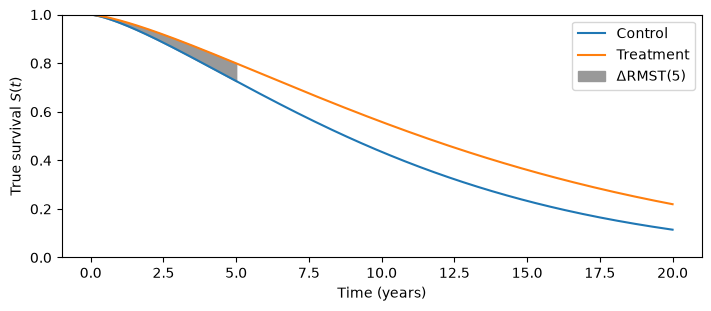

True RMST(5): control 4.391, treatment 4.561, difference 0.170 years


In [3]:
both_arms = jnp.array([0.0, 1.0])  # control, treatment
truth = survjax.ProportionalHazards(
    baseline=survjax.Weibull(shape=1.38, scale=11.42), log_hazard_ratio=jnp.log(0.7) * both_arms
)
times = jnp.linspace(0, 20, 201)
curves = truth.survival_grid(times)  # grid shape: (time, arm)

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(times, curves, label=["Control", "Treatment"])
up_to_5 = times <= 5
ax.fill_between(times[up_to_5], curves[up_to_5, 0], curves[up_to_5, 1], color="0.6",
                label="ΔRMST(5)")
ax.set(xlabel="Time (years)", ylabel="True survival $S(t)$", ylim=(0, 1))
ax.legend()
plt.show()

true_rmst5 = truth.rmst(5.0)
print(f"True RMST(5): control {true_rmst5[0]:.3f}, treatment {true_rmst5[1]:.3f}, "
      f"difference {true_rmst5[1] - true_rmst5[0]:.3f} years")

Over the first five years, treated patients gain on average 0.17 years, about two months, of event-free time. Most patients in both arms are still event-free at five years, which is why the difference is small compared to the horizon.

## The likelihood as a NumPyro factor

We define a model in NumPyro that samples the three parameters on the log scale, builds the survjax survival distribution, and adds the per-patient log likelihood to the target with `numpyro.factor`. The factor receives the vector of 300 terms, one per patient, inside the observation plate, which tells NumPyro that the terms are conditionally independent. Edit the priors here to see how they change the results.

The optional `compute_rmst` branch declares the per-arm RMST as deterministic sites; we come back to it below.

In [4]:
def model(data, arm, compute_rmst=False, tau=5.0, tau_grid=None):
    log_k = numpyro.sample("log_k", distributions.Normal(0, 5))
    log_b0 = numpyro.sample("log_b0", distributions.Normal(0, 5))
    gamma = numpyro.sample("gamma", distributions.Normal(0, 5))

    base = survjax.Weibull.from_log(log_shape=log_k, log_scale=log_b0)
    survival = survjax.ProportionalHazards(baseline=base, log_hazard_ratio=gamma * arm)
    with numpyro.plate("observations", len(data)):
        numpyro.factor("survival", survival.log_likelihood(data))

    if compute_rmst:
        per_arm = survjax.ProportionalHazards(baseline=base, log_hazard_ratio=gamma * jnp.array([0.0, 1.0]))
        numpyro.deterministic("rmst_tau", per_arm.rmst(tau))                  # (2,)
        numpyro.deterministic("rmst_curve", per_arm.rmst(tau_grid[:, None]))  # (m, 2)

NumPyro then samples the posterior with NUTS: four chains, each with `NUM_DRAWS` warmup and `NUM_DRAWS` retained draws. Check that there are no divergent transitions, that $\hat R$ is close to 1 and that the effective sample sizes (`n_eff`) are large.

In [5]:
mcmc = MCMC(NUTS(model), num_warmup=NUM_DRAWS, num_samples=NUM_DRAWS, num_chains=4,
            progress_bar=False)
mcmc.run(jax.random.key(1), data, arm)
mcmc.print_summary()  # also reports the number of divergent transitions
samples = mcmc.get_samples()  # {"log_k": (S,), "log_b0": (S,), "gamma": (S,)}


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     gamma     -0.17      0.17     -0.17     -0.45      0.11   2317.42      1.00
    log_b0      2.50      0.09      2.49      2.35      2.65   2248.84      1.00
     log_k      0.26      0.07      0.26      0.14      0.37   2613.56      1.00

Number of divergences: 0


## The posterior is a batch of distributions

The posterior is a set of $S$ draws of $(k, b_0, \gamma)$; with the default settings $S=4{,}000$. In survjax a distribution with array-valued parameters is a batch of distributions, so we can create one distribution with the draws and treatment arm ($a=0, a=1$) and get batch shape (draw, arm):

In [6]:
base = survjax.Weibull.from_log(
    log_shape=samples["log_k"][:, None], log_scale=samples["log_b0"][:, None]
)
posterior = survjax.ProportionalHazards(
    baseline=base, log_hazard_ratio=samples["gamma"][:, None] * jnp.array([0.0, 1.0])
)
rmst5 = posterior.rmst(5.0)          # (S, 2)
delta5 = rmst5[:, 1] - rmst5[:, 0]   # paired within each draw, (S,)

low, high = jnp.quantile(delta5, jnp.array([0.025, 0.975]))
print(f"ΔRMST(5): mean {delta5.mean():.3f} years, 95% interval [{low:.3f}, {high:.3f}]")
print(f"P(ΔRMST(5) > 0) = {(delta5 > 0).mean():.3f}")

ΔRMST(5): mean 0.091 years, 95% interval [-0.087, 0.272]
P(ΔRMST(5) > 0) = 0.840


To propagate the uncertainty correctly, we compute every summary within each draw, keep the two arms of a draw paired, and summarize only at the end: the posterior mean, credible interval and $P(\Delta\mathrm{RMST}(5)>0)$ are all summaries of the values in `delta5`.

The same quantities can also be declared inside the model, as deterministic sites. The `compute_rmst` flag keeps them out of the sampler, where they are not needed, and NumPyro's `Predictive` fills them in afterwards for every posterior draw. Both routes give the same values:

In [7]:
tau_grid = jnp.linspace(0.0, 13.0, 101)  # horizons up to about the 90th percentile of follow-up
predictive = Predictive(model, posterior_samples=samples, return_sites=["rmst_tau"])
sites = predictive(jax.random.key(0), data, arm, compute_rmst=True, tau_grid=tau_grid)
print("Largest difference between the routes:", float(jnp.abs(sites["rmst_tau"] - rmst5).max()), "years")

Largest difference between the routes: 1.4210854715202004e-14 years


## Results

The posterior summaries, with the true values:

In [8]:
summaries = {
    "Shape k": (jnp.exp(samples["log_k"]), 1.38),
    "Hazard ratio": (jnp.exp(samples["gamma"]), 0.7),
    "RMST(5), control": (rmst5[:, 0], true_rmst5[0]),
    "RMST(5), treatment": (rmst5[:, 1], true_rmst5[1]),
    "ΔRMST(5)": (delta5, true_rmst5[1] - true_rmst5[0]),
}
print(f"{'':20}{'truth':>8}{'mean':>8}{'sd':>8}   95% credible interval")
for name, (values, true_value) in summaries.items():
    low, high = jnp.quantile(values, jnp.array([0.025, 0.975]))
    print(f"{name:20}{true_value:8.3f}{values.mean():8.3f}{values.std(ddof=1):8.3f}   "
          f"[{low:.3f}, {high:.3f}]")

                       truth    mean      sd   95% credible interval
Shape k                1.380   1.296   0.092   [1.121, 1.483]
Hazard ratio           0.700   0.855   0.147   [0.606, 1.175]
RMST(5), control       4.391   4.367   0.088   [4.182, 4.528]
RMST(5), treatment     4.561   4.458   0.079   [4.292, 4.601]
ΔRMST(5)               0.170   0.091   0.092   [-0.087, 0.272]


The posterior survival curves per arm, with 95% pointwise credible bands, the true curves and the observed Kaplan–Meier curves. The Kaplan–Meier estimate is a small helper written here; it is not part of survjax.

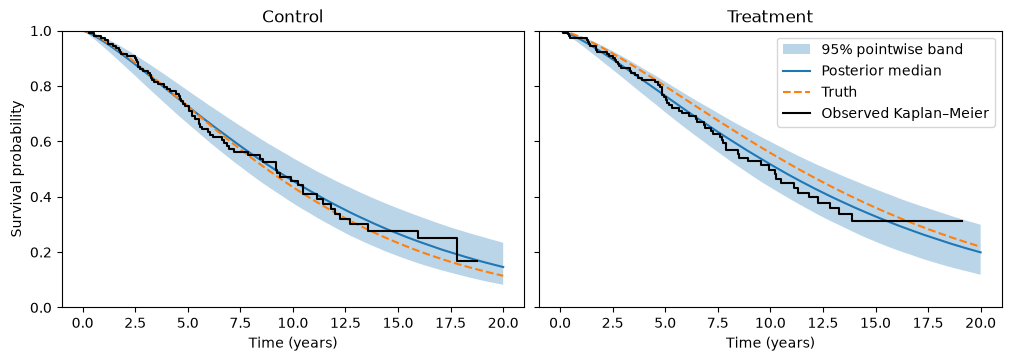

In [9]:
def kaplan_meier(time, event):
    # Product-limit estimate as step coordinates; censorings tied with an event stay at risk.
    time, event = np.asarray(time), np.asarray(event)
    event_times = np.unique(time[event])
    deaths = np.array([np.sum((time == t) & event) for t in event_times])
    at_risk = np.array([np.sum(time >= t) for t in event_times])
    survival = np.cumprod(1 - deaths / at_risk)
    return np.r_[0.0, event_times, time.max()], np.r_[1.0, survival, survival[-1]]


survival = posterior.survival_grid(times)  # (time, S, 2)
low, median, high = jnp.quantile(survival, jnp.array([0.025, 0.5, 0.975]), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for a, (ax, label) in enumerate(zip(axes, ["Control", "Treatment"], strict=True)):
    ax.fill_between(times, low[:, a], high[:, a], alpha=0.3, label="95% pointwise band")
    ax.plot(times, median[:, a], label="Posterior median")
    ax.plot(times, curves[:, a], "--", color="C1", label="Truth")
    ax.step(*kaplan_meier(data.lower[arm == a], data.exact[arm == a]), where="post",
            color="black", label="Observed Kaplan–Meier")
    ax.set(title=label, xlabel="Time (years)", ylim=(0, 1))
axes[0].set_ylabel("Survival probability")
axes[1].legend()
plt.show()

The posterior distribution of $\Delta\mathrm{RMST}(5)$, with its 95% credible interval and the true value. Positive values favour treatment.

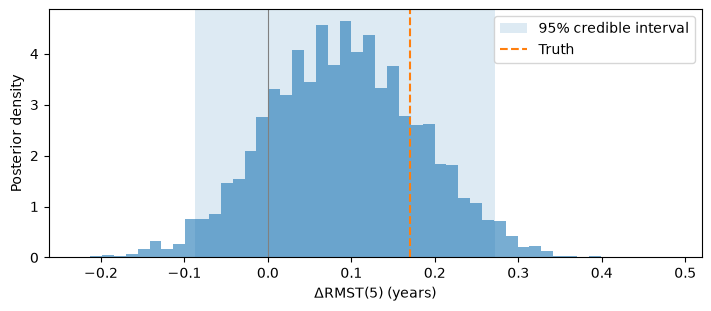

In [10]:
low, high = jnp.quantile(delta5, jnp.array([0.025, 0.975]))
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.hist(delta5, bins=50, density=True, alpha=0.6)
ax.axvspan(low, high, alpha=0.15, label="95% credible interval")
ax.axvline(true_rmst5[1] - true_rmst5[0], color="C1", linestyle="--", label="Truth")
ax.axvline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="ΔRMST(5) (years)", ylabel="Posterior density")
ax.legend()
plt.show()

Putting the horizons on a leading axis evaluates RMST for every horizon, draw and arm at once:

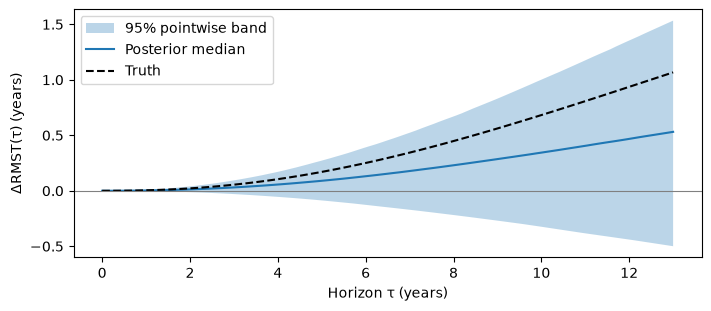

In [11]:
rmst_curve = posterior.rmst(tau_grid[:, None, None])     # (horizon, S, 2)
delta_curve = rmst_curve[..., 1] - rmst_curve[..., 0]    # (horizon, S)
low, median, high = jnp.quantile(delta_curve, jnp.array([0.025, 0.5, 0.975]), axis=1)
true_rmst = truth.rmst(tau_grid[:, None])                # (horizon, 2)

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.fill_between(tau_grid, low, high, alpha=0.3, label="95% pointwise band")
ax.plot(tau_grid, median, label="Posterior median")
ax.plot(tau_grid, true_rmst[:, 1] - true_rmst[:, 0], "k--", label="Truth")
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="Horizon τ (years)", ylabel="ΔRMST(τ) (years)")
ax.legend(loc="upper left")
plt.show()

To go further, add covariates to the linear predictor, `log_hazard_ratio=X @ beta`, try another baseline distribution, or report RMST at several horizons from the same draws. See the [proportional hazards](../../docs/proportional-hazards.md), [RMST](../../docs/rmst.md) and [likelihood](../../docs/likelihood.md) documentation.

## Running this notebook

From the repository root, run `uv run --group docs --group examples jupyter lab examples/bayesian_rmst/bayesian-rmst.ipynb`, then **Restart Kernel and Run All Cells** in a fresh Python 3 kernel. The first cell must run before JAX starts: it gives each chain its own CPU device and switches JAX to float64. Sampling takes a few seconds on a laptop CPU; set `NUM_DRAWS = 100` for a quick run. The [command-line runner](README.md) reproduces the committed results of the documentation page.

## References

Hoffman, M. D. and Gelman, A. (2014). The No-U-Turn sampler: adaptively setting path lengths in Hamiltonian Monte Carlo. *Journal of Machine Learning Research* 15, 1593–1623.

Phan, D., Pradhan, N. and Jankowiak, M. (2019). Composable effects for flexible and accelerated probabilistic programming in NumPyro. arXiv:1912.11554.

Royston, P. and Parmar, M. K. B. (2013). Restricted mean survival time: an alternative to the hazard ratio for the design and analysis of randomized trials with a time-to-event outcome. *BMC Medical Research Methodology* 13, 152.

All data in this notebook are synthetic.